In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib
import time
from numpy.random import default_rng

matplotlib.rcParams['figure.dpi'] = 120


In [2]:
bank = pd.read_csv('bank-full.csv', sep=';')
print(f'Shape: {bank.shape}')
print(f'\nColumn dtypes:')
print(bank.dtypes)
print(f'\nActual NaN count: {bank.isna().sum().sum()}')
print(f"Rows containing 'unknown': {(bank == 'unknown').any(axis=1).sum()}")
bank.head()


Shape: (45211, 17)

Column dtypes:
age           int64
job          object
marital      object
education    object
default      object
balance       int64
housing      object
loan         object
contact      object
day           int64
month        object
duration      int64
campaign      int64
pdays         int64
previous      int64
poutcome     object
y            object
dtype: object

Actual NaN count: 0
Rows containing 'unknown': 37369


,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,y
0,58,management,married,tertiary,no,2143,yes,no,unknown,5,may,261,1,-1,0,unknown,no
1,44,technician,single,secondary,no,29,yes,no,unknown,5,may,151,1,-1,0,unknown,no
2,33,entrepreneur,married,secondary,no,2,yes,yes,unknown,5,may,76,1,-1,0,unknown,no
3,47,blue-collar,married,unknown,no,1506,yes,no,unknown,5,may,92,1,-1,0,unknown,no
4,33,unknown,single,unknown,no,1,no,no,unknown,5,may,198,1,-1,0,unknown,no


In [3]:
binary_cols = ['default', 'housing', 'loan']
for col in binary_cols:
    n_unknown = (bank[col] == 'unknown').sum()
    print(f"  '{col}' has {n_unknown} unknown rows ({100*n_unknown/len(bank):.2f}%)")


  'default' has 0 unknown rows (0.00%)
  'housing' has 0 unknown rows (0.00%)
  'loan' has 0 unknown rows (0.00%)


In [4]:
# Binary columns: simple map, no rows lost
binary_cols = ['default', 'housing', 'loan']
for col in binary_cols:
    bank[col] = bank[col].map({'yes': 1, 'no': 0})

# Target
bank['y'] = bank['y'].map({'yes': 1, 'no': 0})

# One-hot encode multi-class text columns
# 'unknown' becomes its own dummy column — no information is thrown away
cat_cols = ['job', 'marital', 'education', 'contact', 'month', 'poutcome']
bank = pd.get_dummies(bank, columns=cat_cols, drop_first=False)

print(f'Shape after encoding: {bank.shape}')
print(f'NaN remaining: {bank.isna().sum().sum()}')
print(f'\nTarget distribution:')
print(bank['y'].value_counts())
print(f'  → Class imbalance: {bank["y"].mean()*100:.1f}% positives')


Shape after encoding: (45211, 49)
NaN remaining: 0

Target distribution:
0    39922
1     5289
Name: y, dtype: int64
  → Class imbalance: 11.7% positives


In [5]:
rng = default_rng(42)

bank_arr = bank.to_numpy().astype(float)
rng.shuffle(bank_arr)

n_bank = bank_arr.shape[0]
split  = int(0.8 * n_bank)

y_col_idx    = bank.columns.get_loc('y')
feature_cols = [i for i in range(bank_arr.shape[1]) if i != y_col_idx]

X_bank_train = bank_arr[:split,  feature_cols]
X_bank_test  = bank_arr[split:,  feature_cols]
y_bank_train = bank_arr[:split,  y_col_idx]
y_bank_test  = bank_arr[split:,  y_col_idx]

print(f'Train: {X_bank_train.shape}')
print(f'Test:  {X_bank_test.shape}')
print(f'Train class balance: {y_bank_train.mean()*100:.1f}% positives')
print(f'Test  class balance: {y_bank_test.mean()*100:.1f}% positives')


Train: (36168, 48)
Test:  (9043, 48)
Train class balance: 11.7% positives
Test  class balance: 11.8% positives


In [6]:
mean_bank             = X_bank_train.mean(axis=0)
std_bank              = X_bank_train.std(axis=0)
std_bank[std_bank==0] = 1   # one-hot columns that are all-zero would give std=0

X_bank_train = (X_bank_train - mean_bank) / std_bank
X_bank_test  = (X_bank_test  - mean_bank) / std_bank

# Prepend a column of ones — this gives beta a free intercept term (beta_0)
X_bank_train = np.hstack([np.ones((X_bank_train.shape[0], 1)), X_bank_train])
X_bank_test  = np.hstack([np.ones((X_bank_test.shape[0],  1)), X_bank_test])

print(f'Final Bank — Train: {X_bank_train.shape}, Test: {X_bank_test.shape}')


Final Bank — Train: (36168, 49), Test: (9043, 49)


In [7]:
occ1 = pd.read_csv('datatraining.txt', index_col=0)
occ2 = pd.read_csv('datatest.txt',     index_col=0)
occ3 = pd.read_csv('datatest2.txt',    index_col=0)
occ  = pd.concat([occ1, occ2, occ3], ignore_index=True)

print(f'Training file:  {occ1.shape}')
print(f'Test file 1:    {occ2.shape}')
print(f'Test file 2:    {occ3.shape}')
print(f'Combined:       {occ.shape}')
print(f'\nNaN count: {occ.isna().sum().sum()}')
print(f'\nTarget distribution:')
print(occ['Occupancy'].value_counts())
occ.head(3)


Training file:  (8143, 7)
Test file 1:    (2665, 7)
Test file 2:    (9752, 7)
Combined:       (20560, 7)

NaN count: 0

Target distribution:
0    15810
1     4750
Name: Occupancy, dtype: int64


,date,Temperature,Humidity,Light,CO2,HumidityRatio,Occupancy
0,2015-02-04 17:51:00,23.18,27.2720,426.0,721.25,0.004793,1
1,2015-02-04 17:51:59,23.15,27.2675,429.5,714.00,0.004783,1
2,2015-02-04 17:53:00,23.15,27.2450,426.0,713.50,0.004779,1


In [8]:
occ['date']        = pd.to_datetime(occ['date'])
occ['hour']        = occ['date'].dt.hour        # 0–23
occ['day_of_week'] = occ['date'].dt.dayofweek   # 0=Monday, 6=Sunday
occ.drop(columns=['date'], inplace=True)

occ.dropna(inplace=True)

print(f'Shape after feature extraction: {occ.shape}')
print(f'Columns: {list(occ.columns)}')
print(f'Hour range: {occ["hour"].min()}–{occ["hour"].max()}')
print(f'Day of week range: {occ["day_of_week"].min()}–{occ["day_of_week"].max()}')
occ.head(3)


Shape after feature extraction: (20560, 8)
Columns: ['Temperature', 'Humidity', 'Light', 'CO2', 'HumidityRatio', 'Occupancy', 'hour', 'day_of_week']
Hour range: 0–23
Day of week range: 0–6


,Temperature,Humidity,Light,CO2,HumidityRatio,Occupancy,hour,day_of_week
0,23.18,27.2720,426.0,721.25,0.004793,1,17,2
1,23.15,27.2675,429.5,714.00,0.004783,1,17,2
2,23.15,27.2450,426.0,713.50,0.004779,1,17,2


In [9]:
rng2    = default_rng(42)
occ_arr = occ.to_numpy().astype(float)
rng2.shuffle(occ_arr)

n_occ     = occ_arr.shape[0]
split_occ = int(0.8 * n_occ)

y_occ_idx = occ.columns.get_loc('Occupancy')
feat_occ  = [i for i in range(occ_arr.shape[1]) if i != y_occ_idx]

X_occ_train = occ_arr[:split_occ, feat_occ]
X_occ_test  = occ_arr[split_occ:, feat_occ]
y_occ_train = occ_arr[:split_occ, y_occ_idx]
y_occ_test  = occ_arr[split_occ:, y_occ_idx]

# Normalize with training stats only
mean_occ            = X_occ_train.mean(axis=0)
std_occ             = X_occ_train.std(axis=0)
std_occ[std_occ==0] = 1

X_occ_train = (X_occ_train - mean_occ) / std_occ
X_occ_test  = (X_occ_test  - mean_occ) / std_occ

# Add bias column
X_occ_train = np.hstack([np.ones((X_occ_train.shape[0], 1)), X_occ_train])
X_occ_test  = np.hstack([np.ones((X_occ_test.shape[0],  1)), X_occ_test])

print(f'Train: {X_occ_train.shape}')
print(f'Test:  {X_occ_test.shape}')
print(f'Train class balance: {y_occ_train.mean()*100:.1f}% positives')
print(f'Test  class balance: {y_occ_test.mean()*100:.1f}% positives')


Train: (16448, 8)
Test:  (4112, 8)
Train class balance: 23.0% positives
Test  class balance: 23.4% positives


In [10]:
def sigmoid(z):
    z = np.clip(z, -500, 500)
    return 1.0 / (1.0 + np.exp(-z))


def log_likelihood(beta, X, y):
    # Numerically stable form: sum( y*z - log(1 + exp(z)) )
    z = X @ beta
    return np.sum(y * z - np.log(1 + np.exp(np.clip(z, -500, 500))))


def log_loss(beta, X, y):
    y_hat = np.clip(sigmoid(X @ beta), 1e-12, 1 - 1e-12)
    return -np.mean(y * np.log(y_hat) + (1 - y) * np.log(1 - y_hat))


def accuracy(beta, X, y):
    return np.mean((sigmoid(X @ beta) >= 0.5) == y)


def gradient_single(beta, xi, yi):
    # Stochastic gradient of log-likelihood for one sample
    return xi * (yi - sigmoid(xi @ beta))


print('Core functions ready.')


Core functions ready.


In [11]:
def learn_logreg_sga_bolddriver(X_train, y_train, X_test, y_test,
                                 mu_init=0.01, imax=200, epsilon=1e-6,
                                 bold_grow=1.1, bold_shrink=0.5, seed=42):
    rng_l = default_rng(seed)
    N, M  = X_train.shape
    beta  = np.zeros(M)
    mu    = mu_init

    ll_prev      = log_likelihood(beta, X_train, y_train)
    ll_diffs     = []
    test_logloss = []

    for epoch in range(imax):
        for i in rng_l.permutation(N):
            g    = gradient_single(beta, X_train[i], y_train[i])
            beta = beta + mu * g          # ascent: ADD the gradient

        ll_curr = log_likelihood(beta, X_train, y_train)
        mu      = mu * (bold_grow if ll_curr > ll_prev else bold_shrink)

        ll_diffs.append(abs(ll_curr - ll_prev))
        test_logloss.append(log_loss(beta, X_test, y_test))

        if ll_diffs[-1] < epsilon:
            print(f'  Converged at epoch {epoch + 1}')
            break

        ll_prev = ll_curr

    return beta, ll_diffs, test_logloss


print('SGA BoldDriver ready.')


SGA BoldDriver ready.


In [12]:
def learn_logreg_sgd_bolddriver(X_train, y_train, X_test, y_test,
                                 mu_init=0.01, imax=200, epsilon=1e-6,
                                 bold_grow=1.1, bold_shrink=0.5, seed=42):
    rng_l     = default_rng(seed)
    N, M      = X_train.shape
    beta      = np.zeros(M)
    mu        = mu_init

    loss_prev    = log_loss(beta, X_train, y_train)
    loss_diffs   = []
    test_logloss = []

    for epoch in range(imax):
        for i in rng_l.permutation(N):
            g_loss = -gradient_single(beta, X_train[i], y_train[i])  # gradient of LOSS
            beta   = beta - mu * g_loss   # descent: SUBTRACT gradient of loss

        loss_curr = log_loss(beta, X_train, y_train)
        mu        = mu * (bold_grow if loss_curr < loss_prev else bold_shrink)

        loss_diffs.append(abs(loss_curr - loss_prev))
        test_logloss.append(log_loss(beta, X_test, y_test))

        if loss_diffs[-1] < epsilon:
            print(f'  Converged at epoch {epoch + 1}')
            break

        loss_prev = loss_curr

    return beta, loss_diffs, test_logloss


print('SGD BoldDriver ready.')


SGD BoldDriver ready.


In [13]:
print('=== Bank Marketing: log-regSGA (BoldDriver) ===')
t0 = time.time()
beta_bank_sga, ll_diffs_bank, test_ll_bank = learn_logreg_sga_bolddriver(
    X_bank_train, y_bank_train, X_bank_test, y_bank_test,
    mu_init=0.01, imax=200, epsilon=1e-6
)
t_bank_sga = time.time() - t0
print(f'Time               : {t_bank_sga:.1f}s')
print(f'Final test log-loss: {test_ll_bank[-1]:.4f}')
print(f'Final test accuracy: {accuracy(beta_bank_sga, X_bank_test, y_bank_test)*100:.2f}%')
print(f'Epochs run         : {len(ll_diffs_bank)}')

print()

print('=== Bank Marketing: SGD (BoldDriver) ===')
t0 = time.time()
beta_bank_sgd, loss_diffs_bank_sgd, test_ll_bank_sgd = learn_logreg_sgd_bolddriver(
    X_bank_train, y_bank_train, X_bank_test, y_bank_test,
    mu_init=0.01, imax=200, epsilon=1e-6
)
t_bank_sgd = time.time() - t0
print(f'Time               : {t_bank_sgd:.1f}s')
print(f'Final test log-loss: {test_ll_bank_sgd[-1]:.4f}')
print(f'Final test accuracy: {accuracy(beta_bank_sgd, X_bank_test, y_bank_test)*100:.2f}%')
print(f'Epochs run         : {len(loss_diffs_bank_sgd)}')


=== Bank Marketing: log-regSGA (BoldDriver) ===
  Converged at epoch 128
Time               : 148.4s
Final test log-loss: 0.2400
Final test accuracy: 90.01%
Epochs run         : 128

=== Bank Marketing: SGD (BoldDriver) ===
  Converged at epoch 17
Time               : 19.1s
Final test log-loss: 0.2401
Final test accuracy: 89.99%
Epochs run         : 17


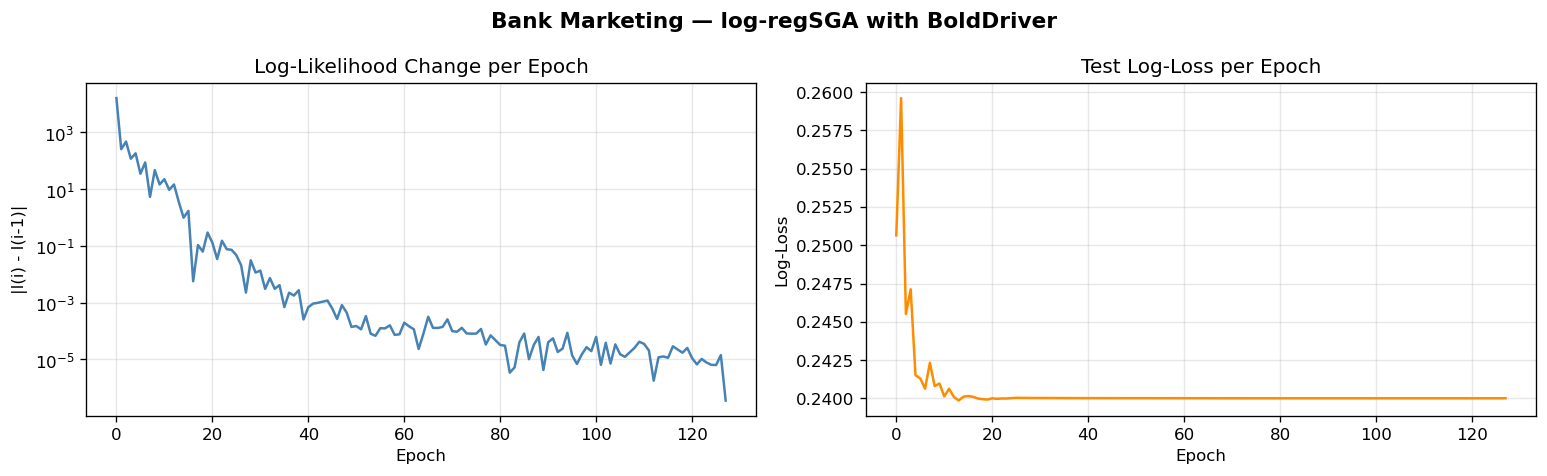

Saved: fig_bank_sga_bolddriver.png


In [14]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
fig.suptitle('Bank Marketing — log-regSGA with BoldDriver', fontsize=13, fontweight='bold')

axes[0].plot(ll_diffs_bank, color='steelblue', linewidth=1.5)
axes[0].set_xlabel('Epoch')
axes[0].set_ylabel('|l(i) - l(i-1)|')
axes[0].set_title('Log-Likelihood Change per Epoch')
axes[0].set_yscale('log')
axes[0].grid(True, alpha=0.3)

axes[1].plot(test_ll_bank, color='darkorange', linewidth=1.5)
axes[1].set_xlabel('Epoch')
axes[1].set_ylabel('Log-Loss')
axes[1].set_title('Test Log-Loss per Epoch')
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig('fig_bank_sga_bolddriver.png', dpi=150, bbox_inches='tight')
plt.show()
print('Saved: fig_bank_sga_bolddriver.png')


In [15]:
print('=== Occupancy: log-regSGA (BoldDriver) ===')
t0 = time.time()
beta_occ_sga, ll_diffs_occ, test_ll_occ = learn_logreg_sga_bolddriver(
    X_occ_train, y_occ_train, X_occ_test, y_occ_test,
    mu_init=0.01, imax=200, epsilon=1e-6
)
t_occ_sga = time.time() - t0
print(f'Time               : {t_occ_sga:.1f}s')
print(f'Final test log-loss: {test_ll_occ[-1]:.4f}')
print(f'Final test accuracy: {accuracy(beta_occ_sga, X_occ_test, y_occ_test)*100:.2f}%')
print(f'Epochs run         : {len(ll_diffs_occ)}')

print()

print('=== Occupancy: SGD (BoldDriver) ===')
t0 = time.time()
beta_occ_sgd, loss_diffs_occ_sgd, test_ll_occ_sgd = learn_logreg_sgd_bolddriver(
    X_occ_train, y_occ_train, X_occ_test, y_occ_test,
    mu_init=0.01, imax=200, epsilon=1e-6
)
t_occ_sgd = time.time() - t0
print(f'Time               : {t_occ_sgd:.1f}s')
print(f'Final test log-loss: {test_ll_occ_sgd[-1]:.4f}')
print(f'Final test accuracy: {accuracy(beta_occ_sgd, X_occ_test, y_occ_test)*100:.2f}%')
print(f'Epochs run         : {len(loss_diffs_occ_sgd)}')


=== Occupancy: log-regSGA (BoldDriver) ===
Time               : 102.7s
Final test log-loss: 0.0436
Final test accuracy: 99.05%
Epochs run         : 200

=== Occupancy: SGD (BoldDriver) ===
  Converged at epoch 13
Time               : 7.0s
Final test log-loss: 0.0437
Final test accuracy: 99.05%
Epochs run         : 13


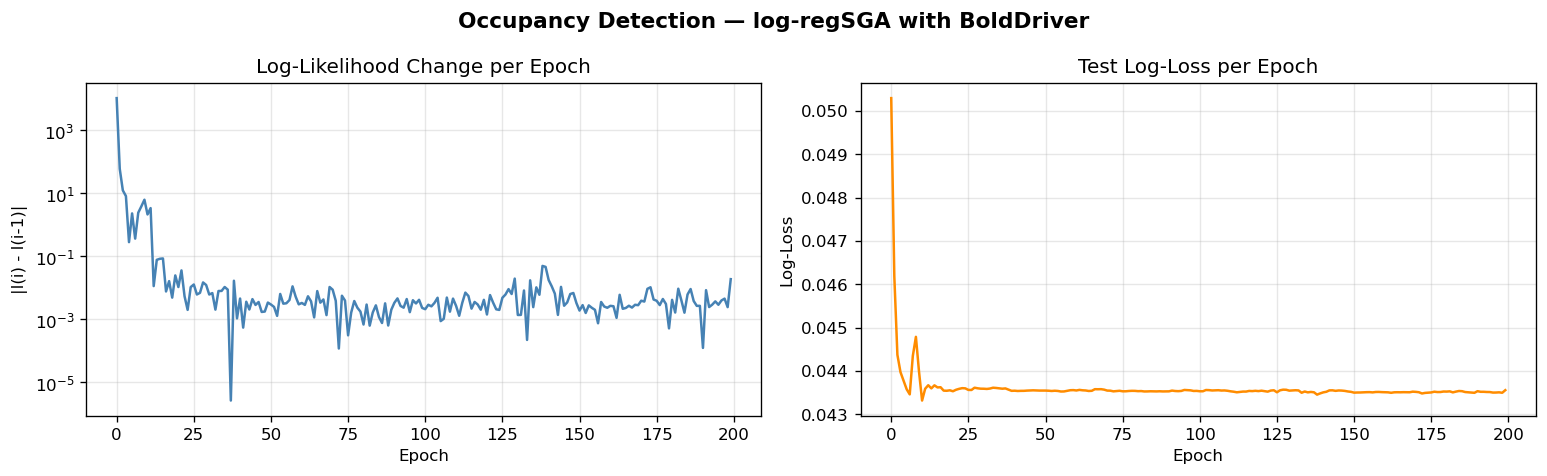

Saved: fig_occ_sga_bolddriver.png


In [16]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
fig.suptitle('Occupancy Detection — log-regSGA with BoldDriver', fontsize=13, fontweight='bold')

axes[0].plot(ll_diffs_occ, color='steelblue', linewidth=1.5)
axes[0].set_xlabel('Epoch')
axes[0].set_ylabel('|l(i) - l(i-1)|')
axes[0].set_title('Log-Likelihood Change per Epoch')
axes[0].set_yscale('log')
axes[0].grid(True, alpha=0.3)

axes[1].plot(test_ll_occ, color='darkorange', linewidth=1.5)
axes[1].set_xlabel('Epoch')
axes[1].set_ylabel('Log-Loss')
axes[1].set_title('Test Log-Loss per Epoch')
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig('fig_occ_sga_bolddriver.png', dpi=150, bbox_inches='tight')
plt.show()
print('Saved: fig_occ_sga_bolddriver.png')


In [17]:
def adagrad_step(g, h, mu0, eps=1e-8):
    """
    Algorithm 3 from the sheet.
    g   : current gradient, shape (M,)
    h   : accumulated squared gradients, shape (M,)
    mu0 : initial global step size
    Returns: per-parameter step sizes (M,), updated h
    """
    h      = h + g ** 2
    mu_vec = mu0 / (np.sqrt(h) + eps)
    return mu_vec, h

print('adagrad_step ready.')


adagrad_step ready.


In [18]:
def learn_logreg_sga_adagrad(X_train, y_train, X_test, y_test,
                              mu0=0.5, imax=200, epsilon=1e-6, seed=42):
    rng_l = default_rng(seed)
    N, M  = X_train.shape
    beta  = np.zeros(M)
    h     = np.zeros(M)   # one history entry per parameter, starts at zero

    ll_prev      = log_likelihood(beta, X_train, y_train)
    ll_diffs     = []
    test_logloss = []

    for epoch in range(imax):
        for i in rng_l.permutation(N):
            g         = gradient_single(beta, X_train[i], y_train[i])
            mu_vec, h = adagrad_step(g, h, mu0)
            beta      = beta + mu_vec * g   # element-wise: each param has its own step

        ll_curr = log_likelihood(beta, X_train, y_train)
        ll_diffs.append(abs(ll_curr - ll_prev))
        test_logloss.append(log_loss(beta, X_test, y_test))

        if ll_diffs[-1] < epsilon:
            print(f'  Converged at epoch {epoch + 1}')
            break

        ll_prev = ll_curr

    return beta, ll_diffs, test_logloss

print('AdaGrad ready.')


AdaGrad ready.


In [20]:
print('=== Bank Marketing: AdaGrad ===')
t0 = time.time()
beta_bank_ada, ll_diffs_bank_ada, test_ll_bank_ada = learn_logreg_sga_adagrad(
    X_bank_train, y_bank_train, X_bank_test, y_bank_test,
    mu0=0.5, imax=200, epsilon=1e-6
)
t_bank_ada = time.time() - t0
print(f'Time               : {t_bank_ada:.1f}s')
print(f'Final test log-loss: {test_ll_bank_ada[-1]:.4f}')
print(f'Final test accuracy: {accuracy(beta_bank_ada, X_bank_test, y_bank_test)*100:.2f}%')
print(f'Epochs run         : {len(ll_diffs_bank_ada)}')

print()

print('=== Occupancy Detection: AdaGrad ===')
t0 = time.time()
beta_occ_ada, ll_diffs_occ_ada, test_ll_occ_ada = learn_logreg_sga_adagrad(
    X_occ_train, y_occ_train, X_occ_test, y_occ_test,
    mu0=0.5, imax=200, epsilon=1e-6
)
t_occ_ada = time.time() - t0
print(f'Time               : {t_occ_ada:.1f}s')
print(f'Final test log-loss: {test_ll_occ_ada[-1]:.4f}')
print(f'Final test accuracy: {accuracy(beta_occ_ada, X_occ_test, y_occ_test)*100:.2f}%')
print(f'Epochs run         : {len(ll_diffs_occ_ada)}')


=== Bank Marketing: AdaGrad ===
Time               : 269.5s
Final test log-loss: 0.2400
Final test accuracy: 89.94%
Epochs run         : 200

=== Occupancy Detection: AdaGrad ===
Time               : 149.9s
Final test log-loss: 0.0435
Final test accuracy: 99.05%
Epochs run         : 200


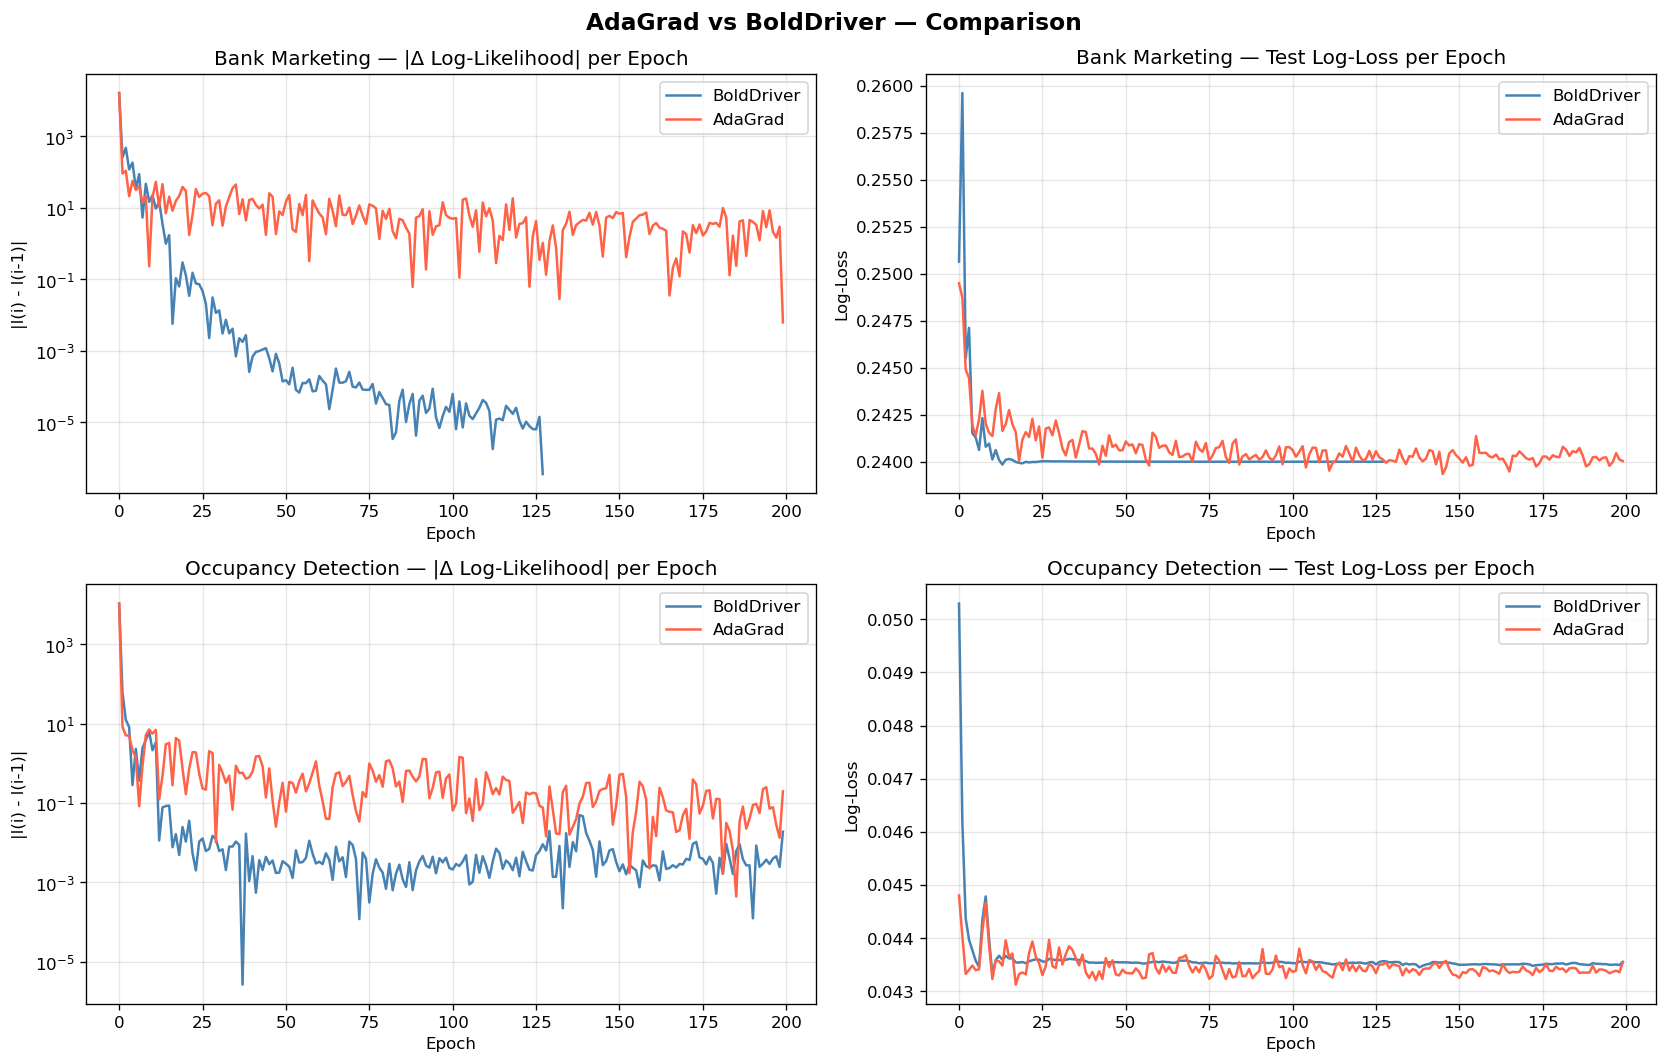

Saved: fig_adagrad_vs_bolddriver.png


In [21]:
fig, axes = plt.subplots(2, 2, figsize=(14, 9))
fig.suptitle('AdaGrad vs BoldDriver — Comparison', fontsize=14, fontweight='bold')

# --- Bank Marketing ---
axes[0,0].plot(ll_diffs_bank,     label='BoldDriver', color='steelblue', linewidth=1.5)
axes[0,0].plot(ll_diffs_bank_ada, label='AdaGrad',    color='tomato',    linewidth=1.5)
axes[0,0].set_title('Bank Marketing — |Δ Log-Likelihood| per Epoch')
axes[0,0].set_xlabel('Epoch')
axes[0,0].set_ylabel('|l(i) - l(i-1)|')
axes[0,0].set_yscale('log')
axes[0,0].legend()
axes[0,0].grid(True, alpha=0.3)

axes[0,1].plot(test_ll_bank,     label='BoldDriver', color='steelblue', linewidth=1.5)
axes[0,1].plot(test_ll_bank_ada, label='AdaGrad',    color='tomato',    linewidth=1.5)
axes[0,1].set_title('Bank Marketing — Test Log-Loss per Epoch')
axes[0,1].set_xlabel('Epoch')
axes[0,1].set_ylabel('Log-Loss')
axes[0,1].legend()
axes[0,1].grid(True, alpha=0.3)

# --- Occupancy Detection ---
axes[1,0].plot(ll_diffs_occ,     label='BoldDriver', color='steelblue', linewidth=1.5)
axes[1,0].plot(ll_diffs_occ_ada, label='AdaGrad',    color='tomato',    linewidth=1.5)
axes[1,0].set_title('Occupancy Detection — |Δ Log-Likelihood| per Epoch')
axes[1,0].set_xlabel('Epoch')
axes[1,0].set_ylabel('|l(i) - l(i-1)|')
axes[1,0].set_yscale('log')
axes[1,0].legend()
axes[1,0].grid(True, alpha=0.3)

axes[1,1].plot(test_ll_occ,     label='BoldDriver', color='steelblue', linewidth=1.5)
axes[1,1].plot(test_ll_occ_ada, label='AdaGrad',    color='tomato',    linewidth=1.5)
axes[1,1].set_title('Occupancy Detection — Test Log-Loss per Epoch')
axes[1,1].set_xlabel('Epoch')
axes[1,1].set_ylabel('Log-Loss')
axes[1,1].legend()
axes[1,1].grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig('fig_adagrad_vs_bolddriver.png', dpi=150, bbox_inches='tight')
plt.show()
print('Saved: fig_adagrad_vs_bolddriver.png')


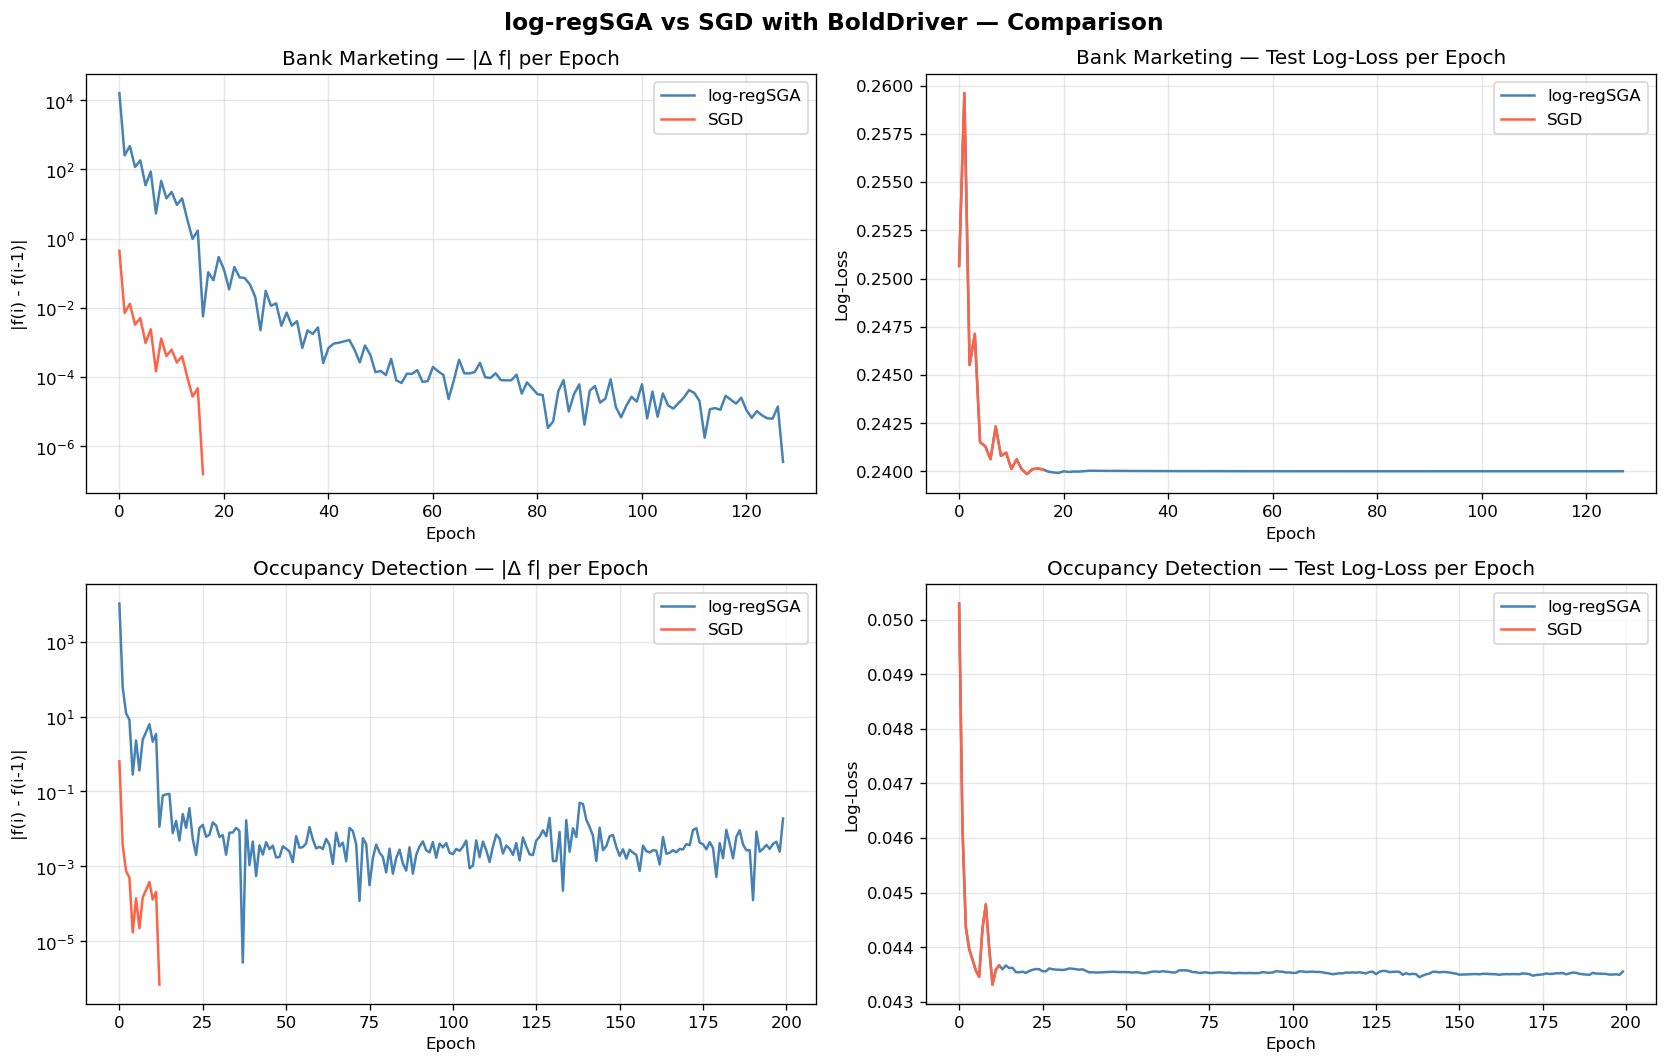

Saved: fig_sga_vs_sgd.png


In [22]:
fig, axes = plt.subplots(2, 2, figsize=(14, 9))
fig.suptitle('log-regSGA vs SGD with BoldDriver — Comparison', fontsize=14, fontweight='bold')

axes[0,0].plot(ll_diffs_bank,        label='log-regSGA', color='steelblue', linewidth=1.5)
axes[0,0].plot(loss_diffs_bank_sgd,  label='SGD',        color='tomato',    linewidth=1.5)
axes[0,0].set_title('Bank Marketing — |Δ f| per Epoch')
axes[0,0].set_xlabel('Epoch')
axes[0,0].set_ylabel('|f(i) - f(i-1)|')
axes[0,0].set_yscale('log')
axes[0,0].legend()
axes[0,0].grid(True, alpha=0.3)

axes[0,1].plot(test_ll_bank,     label='log-regSGA', color='steelblue', linewidth=1.5)
axes[0,1].plot(test_ll_bank_sgd, label='SGD',        color='tomato',    linewidth=1.5)
axes[0,1].set_title('Bank Marketing — Test Log-Loss per Epoch')
axes[0,1].set_xlabel('Epoch')
axes[0,1].set_ylabel('Log-Loss')
axes[0,1].legend()
axes[0,1].grid(True, alpha=0.3)

axes[1,0].plot(ll_diffs_occ,        label='log-regSGA', color='steelblue', linewidth=1.5)
axes[1,0].plot(loss_diffs_occ_sgd,  label='SGD',        color='tomato',    linewidth=1.5)
axes[1,0].set_title('Occupancy Detection — |Δ f| per Epoch')
axes[1,0].set_xlabel('Epoch')
axes[1,0].set_ylabel('|f(i) - f(i-1)|')
axes[1,0].set_yscale('log')
axes[1,0].legend()
axes[1,0].grid(True, alpha=0.3)

axes[1,1].plot(test_ll_occ,     label='log-regSGA', color='steelblue', linewidth=1.5)
axes[1,1].plot(test_ll_occ_sgd, label='SGD',        color='tomato',    linewidth=1.5)
axes[1,1].set_title('Occupancy Detection — Test Log-Loss per Epoch')
axes[1,1].set_xlabel('Epoch')
axes[1,1].set_ylabel('Log-Loss')
axes[1,1].legend()
axes[1,1].grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig('fig_sga_vs_sgd.png', dpi=150, bbox_inches='tight')
plt.show()
print('Saved: fig_sga_vs_sgd.png')


In [23]:
from sklearn.linear_model import LogisticRegression

# Bank Marketing
print('=== sklearn LogisticRegression — Bank Marketing ===')
t0 = time.time()
clf_bank = LogisticRegression(max_iter=1000, random_state=42)
clf_bank.fit(X_bank_train, y_bank_train)
t_bank_sklearn = time.time() - t0

y_pred_bank  = clf_bank.predict(X_bank_test)
y_prob_bank  = clf_bank.predict_proba(X_bank_test)[:, 1]
sk_loss_bank = -np.mean(y_bank_test * np.log(np.clip(y_prob_bank, 1e-12, 1-1e-12)) +
                        (1 - y_bank_test) * np.log(np.clip(1 - y_prob_bank, 1e-12, 1-1e-12)))
sk_acc_bank  = np.mean(y_pred_bank == y_bank_test)
print(f'Time          : {t_bank_sklearn:.2f}s')
print(f'Test log-loss : {sk_loss_bank:.4f}')
print(f'Test accuracy : {sk_acc_bank*100:.2f}%')

print()

# Occupancy
print('=== sklearn LogisticRegression — Occupancy Detection ===')
t0 = time.time()
clf_occ = LogisticRegression(max_iter=1000, random_state=42)
clf_occ.fit(X_occ_train, y_occ_train)
t_occ_sklearn = time.time() - t0

y_pred_occ  = clf_occ.predict(X_occ_test)
y_prob_occ  = clf_occ.predict_proba(X_occ_test)[:, 1]
sk_loss_occ = -np.mean(y_occ_test * np.log(np.clip(y_prob_occ, 1e-12, 1-1e-12)) +
                       (1 - y_occ_test) * np.log(np.clip(1 - y_prob_occ, 1e-12, 1-1e-12)))
sk_acc_occ  = np.mean(y_pred_occ == y_occ_test)
print(f'Time          : {t_occ_sklearn:.2f}s')
print(f'Test log-loss : {sk_loss_occ:.4f}')
print(f'Test accuracy : {sk_acc_occ*100:.2f}%')


=== sklearn LogisticRegression — Bank Marketing ===
Time          : 0.29s
Test log-loss : 0.2400
Test accuracy : 90.01%

=== sklearn LogisticRegression — Occupancy Detection ===
Time          : 0.06s
Test log-loss : 0.0436
Test accuracy : 99.05%


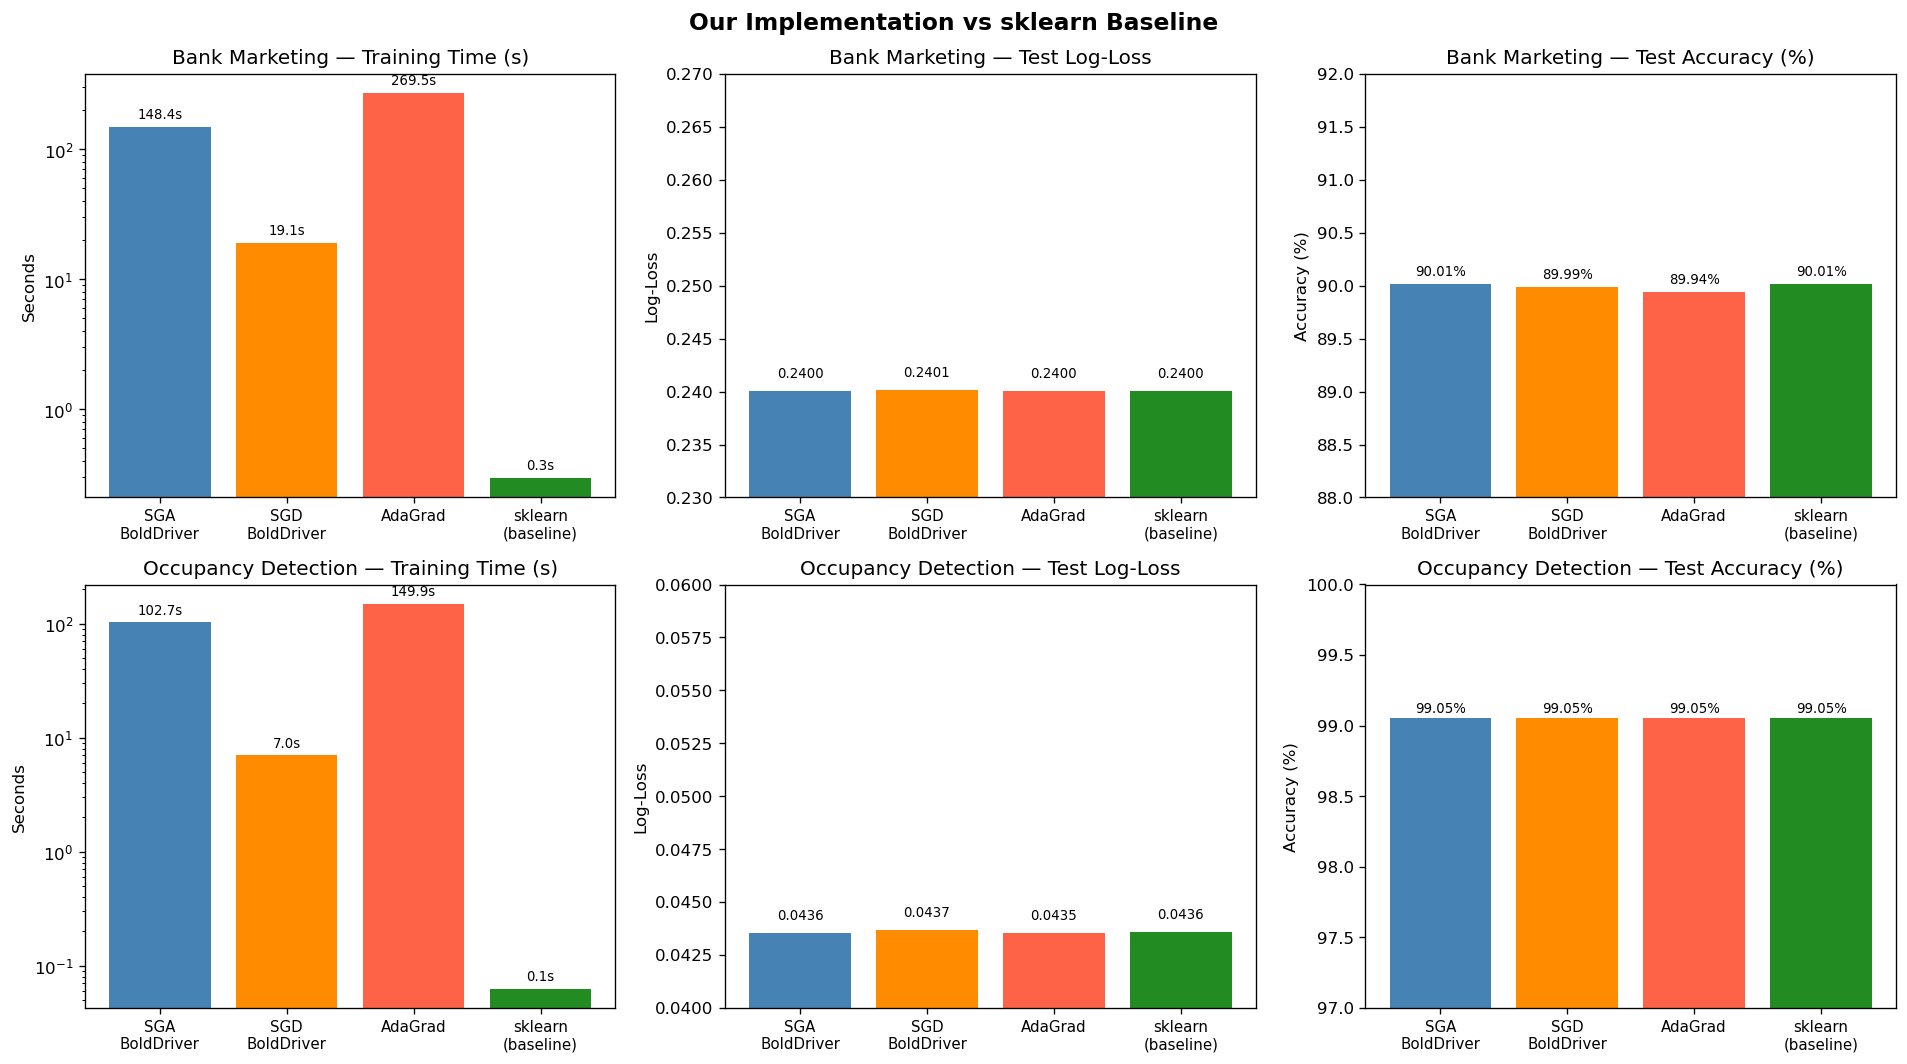

Saved: fig_vs_sklearn.png


In [24]:
methods      = ['SGA\nBoldDriver', 'SGD\nBoldDriver', 'AdaGrad', 'sklearn\n(baseline)']
times_bank   = [t_bank_sga, t_bank_sgd, t_bank_ada, t_bank_sklearn]
times_occ    = [t_occ_sga,  t_occ_sgd,  t_occ_ada,  t_occ_sklearn]
losses_bank  = [test_ll_bank[-1], test_ll_bank_sgd[-1], test_ll_bank_ada[-1], sk_loss_bank]
losses_occ   = [test_ll_occ[-1],  test_ll_occ_sgd[-1],  test_ll_occ_ada[-1],  sk_loss_occ]
accs_bank    = [accuracy(beta_bank_sga, X_bank_test, y_bank_test),
                accuracy(beta_bank_sgd, X_bank_test, y_bank_test),
                accuracy(beta_bank_ada, X_bank_test, y_bank_test),
                sk_acc_bank]
accs_occ     = [accuracy(beta_occ_sga, X_occ_test, y_occ_test),
                accuracy(beta_occ_sgd, X_occ_test, y_occ_test),
                accuracy(beta_occ_ada, X_occ_test, y_occ_test),
                sk_acc_occ]

colors = ['steelblue', 'darkorange', 'tomato', 'forestgreen']
x = np.arange(len(methods))

fig, axes = plt.subplots(2, 3, figsize=(16, 9))
fig.suptitle('Our Implementation vs sklearn Baseline', fontsize=14, fontweight='bold')

for col, (dataset, times, losses, accs) in enumerate([
    ('Bank Marketing',      times_bank, losses_bank, accs_bank),
    ('Occupancy Detection', times_occ,  losses_occ,  accs_occ),
]):
    pass

# --- Row 0: Bank Marketing ---
bars = axes[0,0].bar(x, times_bank, color=colors)
axes[0,0].set_title('Bank Marketing — Training Time (s)')
axes[0,0].set_xticks(x); axes[0,0].set_xticklabels(methods, fontsize=9)
axes[0,0].set_ylabel('Seconds')
axes[0,0].set_yscale('log')
for bar, val in zip(bars, times_bank):
    axes[0,0].text(bar.get_x()+bar.get_width()/2, bar.get_height()*1.1,
                   f'{val:.1f}s', ha='center', va='bottom', fontsize=8)

bars = axes[0,1].bar(x, losses_bank, color=colors)
axes[0,1].set_title('Bank Marketing — Test Log-Loss')
axes[0,1].set_xticks(x); axes[0,1].set_xticklabels(methods, fontsize=9)
axes[0,1].set_ylabel('Log-Loss')
axes[0,1].set_ylim(0.23, 0.27)
for bar, val in zip(bars, losses_bank):
    axes[0,1].text(bar.get_x()+bar.get_width()/2, bar.get_height()+0.001,
                   f'{val:.4f}', ha='center', va='bottom', fontsize=8)

bars = axes[0,2].bar(x, [a*100 for a in accs_bank], color=colors)
axes[0,2].set_title('Bank Marketing — Test Accuracy (%)')
axes[0,2].set_xticks(x); axes[0,2].set_xticklabels(methods, fontsize=9)
axes[0,2].set_ylabel('Accuracy (%)')
axes[0,2].set_ylim(88, 92)
for bar, val in zip(bars, accs_bank):
    axes[0,2].text(bar.get_x()+bar.get_width()/2, val*100+0.05,
                   f'{val*100:.2f}%', ha='center', va='bottom', fontsize=8)

# --- Row 1: Occupancy ---
bars = axes[1,0].bar(x, times_occ, color=colors)
axes[1,0].set_title('Occupancy Detection — Training Time (s)')
axes[1,0].set_xticks(x); axes[1,0].set_xticklabels(methods, fontsize=9)
axes[1,0].set_ylabel('Seconds')
axes[1,0].set_yscale('log')
for bar, val in zip(bars, times_occ):
    axes[1,0].text(bar.get_x()+bar.get_width()/2, bar.get_height()*1.1,
                   f'{val:.1f}s', ha='center', va='bottom', fontsize=8)

bars = axes[1,1].bar(x, losses_occ, color=colors)
axes[1,1].set_title('Occupancy Detection — Test Log-Loss')
axes[1,1].set_xticks(x); axes[1,1].set_xticklabels(methods, fontsize=9)
axes[1,1].set_ylabel('Log-Loss')
axes[1,1].set_ylim(0.04, 0.06)
for bar, val in zip(bars, losses_occ):
    axes[1,1].text(bar.get_x()+bar.get_width()/2, bar.get_height()+0.0005,
                   f'{val:.4f}', ha='center', va='bottom', fontsize=8)

bars = axes[1,2].bar(x, [a*100 for a in accs_occ], color=colors)
axes[1,2].set_title('Occupancy Detection — Test Accuracy (%)')
axes[1,2].set_xticks(x); axes[1,2].set_xticklabels(methods, fontsize=9)
axes[1,2].set_ylabel('Accuracy (%)')
axes[1,2].set_ylim(97, 100)
for bar, val in zip(bars, accs_occ):
    axes[1,2].text(bar.get_x()+bar.get_width()/2, val*100+0.02,
                   f'{val*100:.2f}%', ha='center', va='bottom', fontsize=8)

plt.tight_layout()
plt.savefig('fig_vs_sklearn.png', dpi=150, bbox_inches='tight')
plt.show()
print('Saved: fig_vs_sklearn.png')


In [25]:
print('=' * 75)
print(f'{"Method":<20} {"Dataset":<22} {"LogLoss":>8} {"Accuracy":>9} {"Time(s)":>9}')
print('=' * 75)

rows = [
    ('SGA BoldDriver',  'Bank Marketing',      test_ll_bank[-1],     accuracy(beta_bank_sga, X_bank_test, y_bank_test), t_bank_sga),
    ('SGD BoldDriver',  'Bank Marketing',      test_ll_bank_sgd[-1], accuracy(beta_bank_sgd, X_bank_test, y_bank_test), t_bank_sgd),
    ('AdaGrad',         'Bank Marketing',      test_ll_bank_ada[-1], accuracy(beta_bank_ada, X_bank_test, y_bank_test), t_bank_ada),
    ('sklearn',         'Bank Marketing',      sk_loss_bank,          sk_acc_bank,                                       t_bank_sklearn),
    ('-'*20,            '-'*22,                '-'*8,                 '-'*9,                                             '-'*9),
    ('SGA BoldDriver',  'Occupancy Detection', test_ll_occ[-1],      accuracy(beta_occ_sga, X_occ_test, y_occ_test),    t_occ_sga),
    ('SGD BoldDriver',  'Occupancy Detection', test_ll_occ_sgd[-1],  accuracy(beta_occ_sgd, X_occ_test, y_occ_test),    t_occ_sgd),
    ('AdaGrad',         'Occupancy Detection', test_ll_occ_ada[-1],  accuracy(beta_occ_ada, X_occ_test, y_occ_test),    t_occ_ada),
    ('sklearn',         'Occupancy Detection', sk_loss_occ,           sk_acc_occ,                                        t_occ_sklearn),
]

for row in rows:
    if row[0].startswith('-'):
        print('-' * 75)
    else:
        method, dataset, loss, acc, t = row
        print(f'{method:<20} {dataset:<22} {loss:>8.4f} {acc*100:>8.2f}% {t:>9.2f}s')

print('=' * 75)


Method               Dataset                 LogLoss  Accuracy   Time(s)
SGA BoldDriver       Bank Marketing           0.2400    90.01%    148.36s
SGD BoldDriver       Bank Marketing           0.2401    89.99%     19.10s
AdaGrad              Bank Marketing           0.2400    89.94%    269.47s
sklearn              Bank Marketing           0.2400    90.01%      0.29s
---------------------------------------------------------------------------
SGA BoldDriver       Occupancy Detection      0.0436    99.05%    102.70s
SGD BoldDriver       Occupancy Detection      0.0437    99.05%      6.99s
AdaGrad              Occupancy Detection      0.0435    99.05%    149.94s
sklearn              Occupancy Detection      0.0436    99.05%      0.06s
